In [1]:
import os
import sys

assert "jax" not in sys.modules, "jax already imported: you must restart your runtime"
os.environ['XLA_FLAGS'] = "--xla_force_host_platform_device_count=4"

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
from matplotlib.ticker import FuncFormatter
import pandas as pd

from epiweeks import Week

import jax
import jax.numpy as jnp
from jax.random import PRNGKey
from jax.typing import ArrayLike

import numpyro
import numpyro.distributions as dist

from pyrenew import model, process, latent, randomvariable, observation
from pyrenew.deterministic import DeterministicPMF,DeterministicVariable
import pyrenew.transformation as t
from pyrenew.randomvariable import TransformedVariable
from pyrenew.metaclass import RandomVariable
from pyrenew.randomvariable import DistributionalVariable
from pyrenew.latent import (
    Infections,
    InfectionInitializationProcess,
    InitializeInfectionsExponentialGrowth,
    InfectionsWithFeedback
)

import arviz as az


/Users/jingjieong/Projects/PyRenew/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Util functions

In [3]:
## plot utils
def format_quarterly_axis(ax):
    """
    Format a Matplotlib time axis to show quarterly ticks (Jan, Apr, Jul, Oct),
    with the year label shown only under January.
    """
    locator = mdates.MonthLocator(bymonth=[1, 4, 7, 10])
    ax.xaxis.set_major_locator(locator)

    def _custom_fmt(x, pos):
        date = mdates.num2date(x)
        if date.month == 1:
            return f"{date.strftime('%b')}\n{date.year}"
        else:
            return date.strftime('%b')

    ax.xaxis.set_major_formatter(FuncFormatter(_custom_fmt))
    return ax

def conv(a: ArrayLike, b: ArrayLike) -> ArrayLike:
    """
    Helper function for convolution.
    """
    
    m = len(a)
    n = len(b)
    c = nc = np.zeros(m + n - 1)

    for i in range(m):       # Python index starts at idx
        for j in range(n):
            c[i + j] += a[i] * b[j]  # no -1 needed
    return c

def discretise_delay(distribution, max_delay: int) -> ArrayLike:
    """
    Daily PMF for a continuous delay distribution using centred bins:
    P(k - 0.5 <= T < k + 0.5) for k = 0..max_delay-1 (the k = 0 bin is [0, 0.5)),
    renormalised to sum to 1. Index k corresponds to a delay of k days.
    """
    edges = jnp.concatenate([jnp.array([0.0]), jnp.arange(max_delay) + 0.5])
    pmf = jnp.diff(distribution.cdf(edges))
    return pmf / pmf.sum()

## Data

In [4]:
## New read method: influenza data (incl. severe cases) now lives in the `flu_d` tab of agg_ari_ili.xlsx
flu_d = pd.read_excel('../sg_data/agg_ari_ili.xlsx', sheet_name='flu_d')
d_main = pd.read_excel('../sg_data/agg_ari_ili.xlsx', sheet_name='d')
# Rename to the same column names used by the old read method
flu_d = flu_d.rename(columns={
    'YEAR': 'year',
    'EPI-WEEK': 'epi_week',
    'OVERALL_NO. OF ARI SAMPLES': 'ari_samples',
    'OVERALL_NO. OF INFLUENZA POSITIVE ARI SAMPLES': 'ari_influenza_pos',
    'OVERALL_NO. OF ILI SAMPLES': 'ili_samples',
    'OVERALL_NO. OF INFLUENZA POSITIVE ILI SAMPLES': 'ili_influenza_pos',
    'Estimated influenza cases': 'est_flu_cases_x5',
    'Flu Positivity (ARI)': 'ari_influenza_positivity',
    'Flu posivitiy (ILI)': 'ili_influenza_positivity',
    'No. of severely ill influenza cases (including deaths)': 'severe_flu',
    'Deaths only': 'deaths',
})

d = flu_d.copy()

# Apply the Week conversion to each row
def get_dates(row):
    try:
        # cast to int: apply(axis=1) upcasts mixed int/float rows to float, which epiweeks rejects
        epi_week = Week(int(row['year']), int(row['epi_week']))
        return pd.Series({
            'start_date': epi_week.startdate(),
            'end_date': epi_week.enddate()
        })
    except Exception as e:
        return pd.Series({
            'start_date': None,
            'end_date': None
        })

# Apply the function and combine results
date_cols = d.apply(get_dates, axis=1)
d = pd.concat([d, date_cols], axis=1)

d['start_date'] = pd.to_datetime(d['start_date'])
d['end_date'] = pd.to_datetime(d['end_date'])

d['year_week'] = d['year'].astype(str) + "-" + d['epi_week'].astype(str)

# Recompute positivity from counts (full precision; the sheet columns are rounded to 3 dp)
d['ili_influenza_positivity'] = d['ili_influenza_pos'] / d['ili_samples']
d['ari_influenza_positivity'] = d['ari_influenza_pos'] / d['ari_samples']

# est_flu_cases = polyclinic ARI attendances x ARI influenza positivity
# (= estimated polyclinic-attributed influenza cases; rounded to integer counts at fit time)
d['poly_ari_attendances'] = d_main['poly_ari_attendances']
d['est_flu_cases'] = d['poly_ari_attendances'] * d['ari_influenza_positivity']

### Surv period

In [5]:
surv_period = {'start': ['2023-18','2023-44','2024-18','2024-44','2025-18','2025-44'],
              'end': ['2023-43','2024-17','2024-43','2025-17','2025-43','2026-17']}

surv_period2 = {'start': ['2023-10','2023-31','2024-2','2024-24','2024-49','2025-33','2026-33'],
              'end': ['2023-17','2023-32','2024-8','2024-31','2025-07','2025-48']}

surv_period3 = {'start': ['2023-1','2023-23','2023-46','2024-18','2024-41','2025-21','2026-11'],
              'end': ['2023-22','2023-45','2024-17','2024-40','2025-20','2026-10','2026-39']}

### Visualising the pre-defined surveillance period

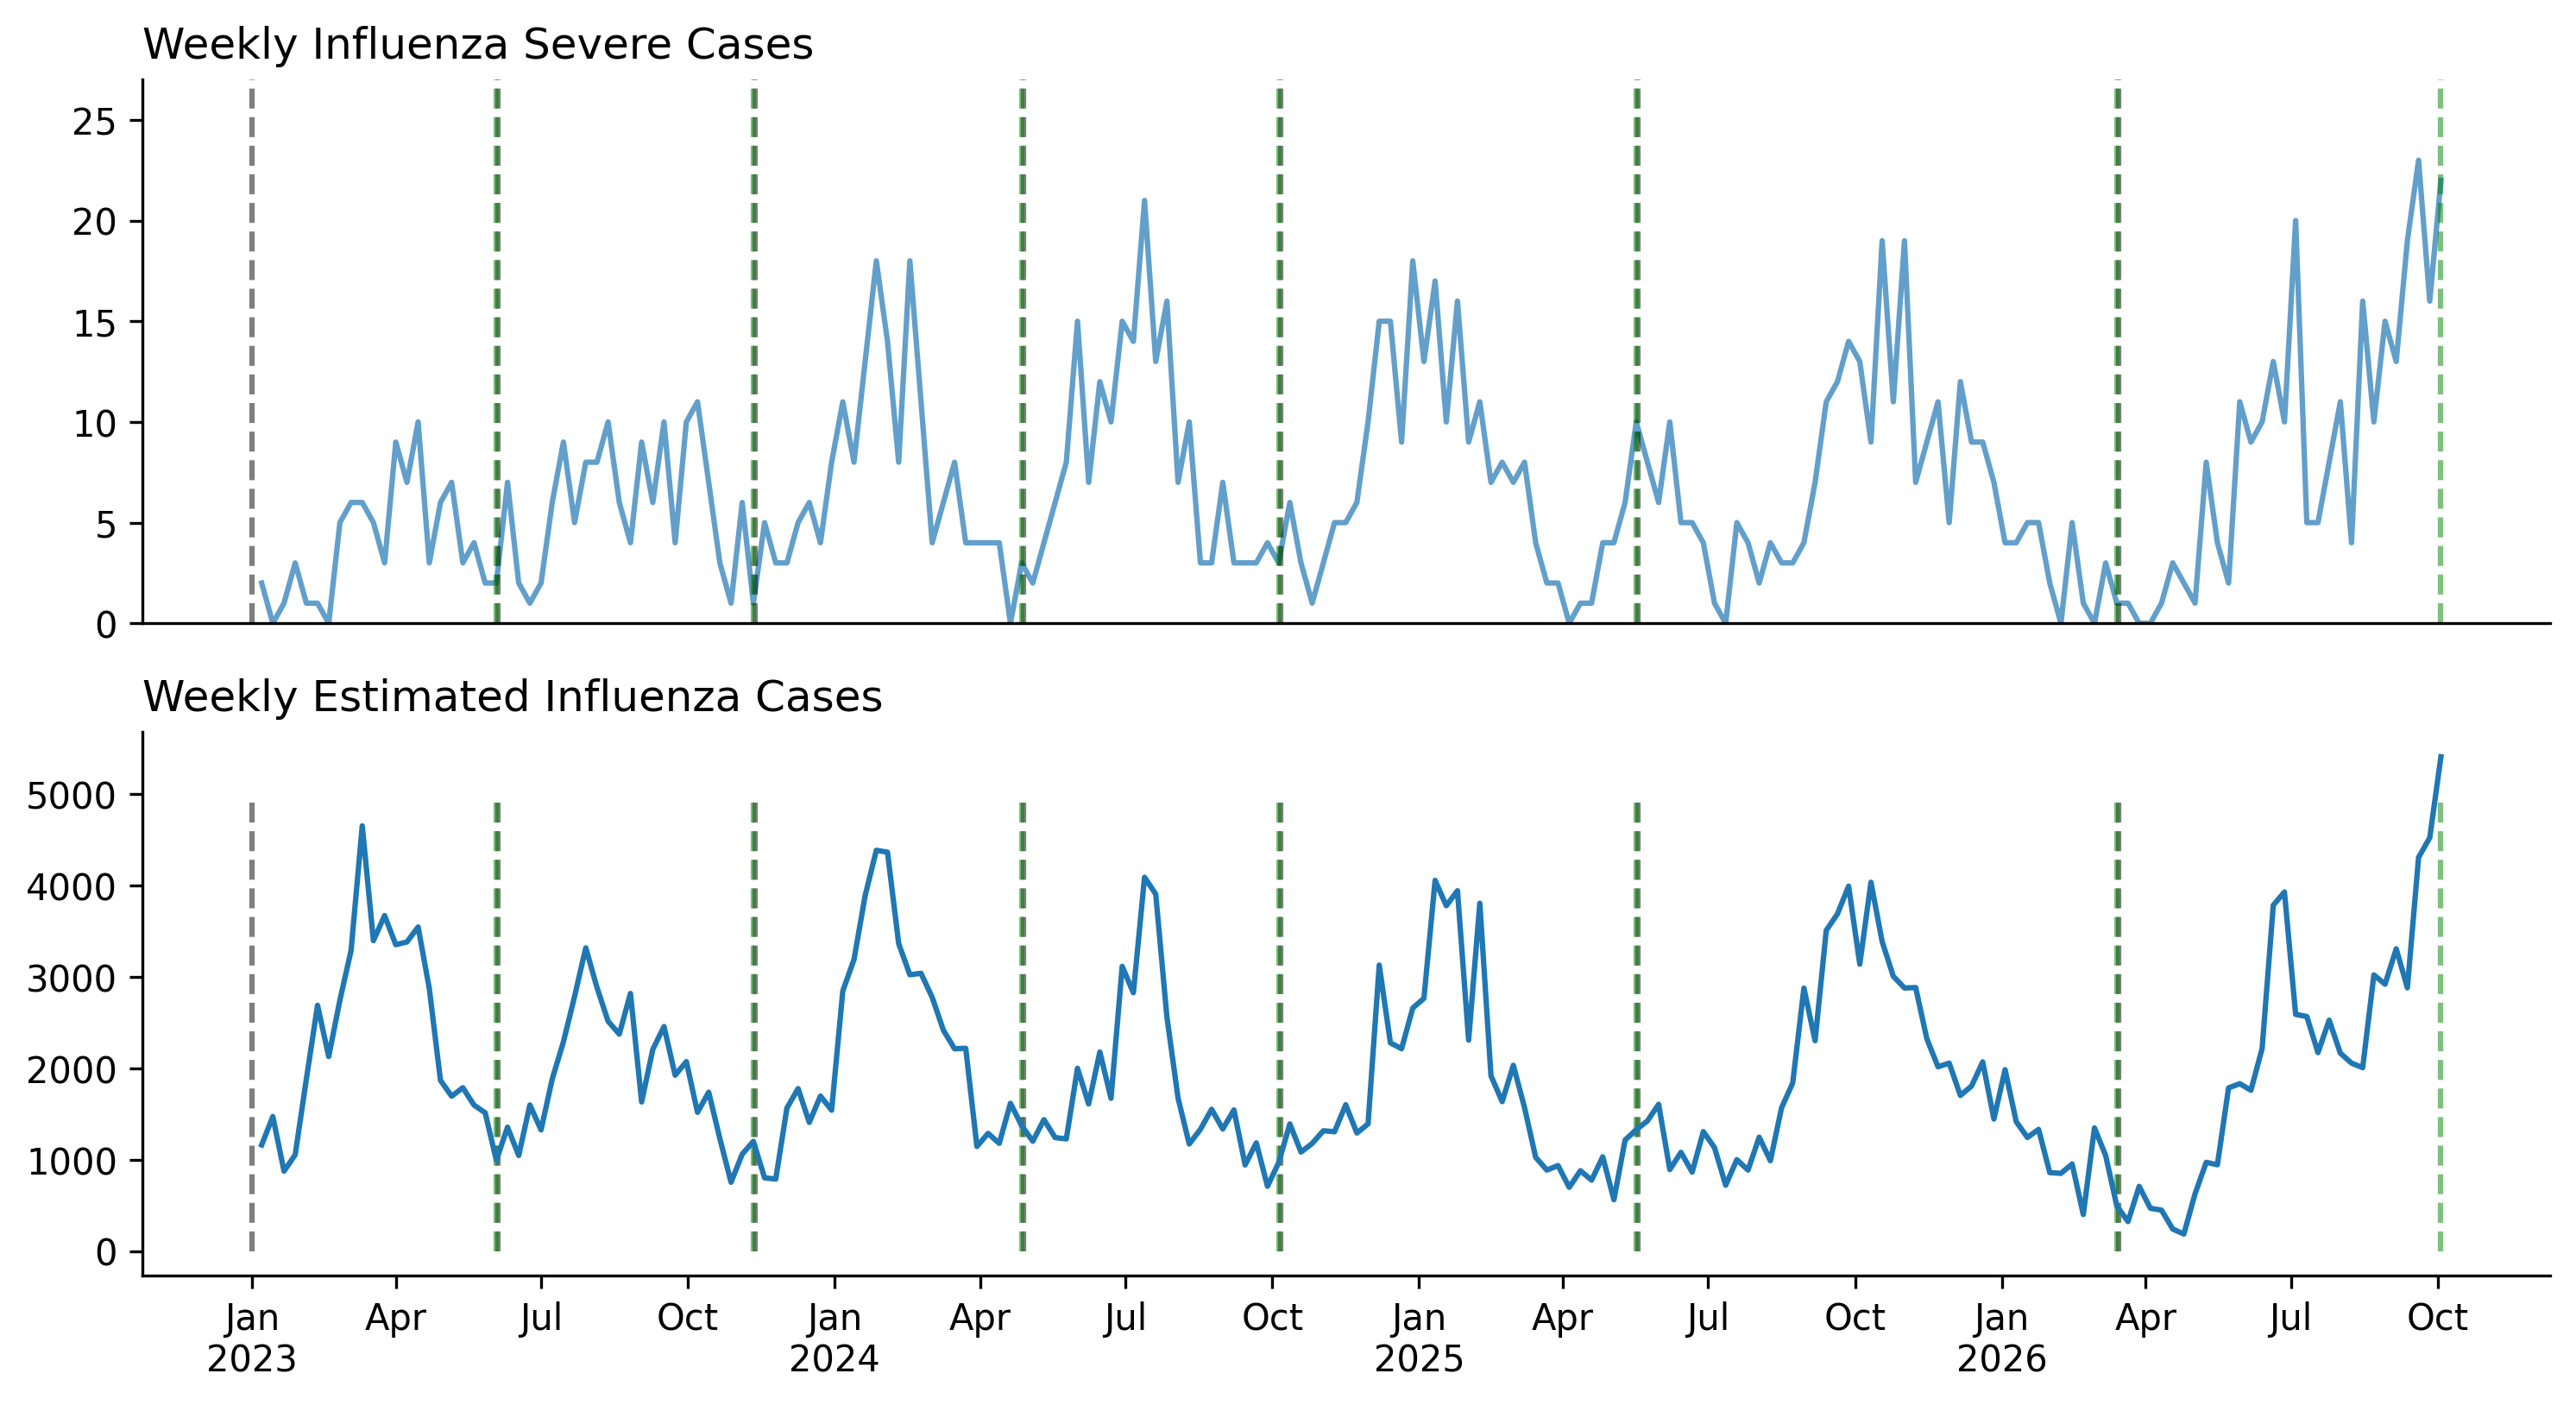

In [6]:
fig,ax = plt.subplots(2,1,figsize = (12,6),dpi=300)
plt.subplots_adjust(hspace = 0.2)

ax[0].plot(d['end_date'],d['severe_flu'], alpha = 0.7)

for v in surv_period3['start']:
        ax[0].vlines(x = d[d['year_week'] == v]['start_date'], ymin = 0, ymax = 30, linestyles='dashed', alpha = 0.5, color = 'black')
        ax[1].vlines(x = d[d['year_week'] == v]['start_date'], ymin = 0, ymax = 5000, linestyles='dashed', alpha = 0.5, color = 'black')

for v in surv_period3['end']:
        ax[0].vlines(x = d[d['year_week'] == v]['end_date'], ymin = 0, ymax = 30, linestyles='dashed', alpha = 0.5, color = 'green')
        ax[1].vlines(x = d[d['year_week'] == v]['end_date'], ymin = 0, ymax = 5000, linestyles='dashed', alpha = 0.5, color = 'green')

ax[0].set_ylim(0,27)
ax[0].set_xticks([])

ax[1].plot(d['end_date'],d['est_flu_cases'])

for a in ax:
        a.spines['top'].set_visible(False)
        a.spines['right'].set_visible(False)

# ax[1].xaxis.set_major_locator(mdates.MonthLocator())
# ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

format_quarterly_axis(ax[1])

ax[0].set_title("Weekly Influenza Severe Cases", loc = 'left')
ax[1].set_title("Weekly Estimated Influenza Cases", loc = 'left')

plt.show()

### Model 2: Severe cases + Primary care estimated cases

In [7]:
## Delay distributions, discretised to daily PMFs with centred bins (discretise_delay in utils)

## Generation time interval, Gamma(4.55,0.7) mean 3.2, sd = 1.5
# PyRenew convention: gen_int[k] is the probability of a generation interval of k+1 days,
# so the 0-day bin is dropped and the PMF renormalised.
gen_time_dist = dist.Gamma(concentration = 4.55, rate = 1/0.7)
gen_time_norm = discretise_delay(gen_time_dist, 21)[1:]
gen_time_norm = gen_time_norm / gen_time_norm.sum()

gen_time_rv = DeterministicPMF(name = 'gen_int', value = gen_time_norm)

## Incubation, Gamma(2.76,0.65) - Infection to symptoms onset = 1-4 days after infection (CDC)
incub_dist = dist.Gamma(concentration = 2.76, rate = 1/0.65) #mean = 1.8, sd = 1
incub_norm = discretise_delay(incub_dist, 10)

## Onset to severe, Gamma(6.25,1.25) - mean 5 days, sd 2
## (assumed to already include the onset-to-notification lag; severe cases are dated by notification week)
ons_severe_dist = dist.Gamma(concentration = 6.25, rate = 1.25) #mean = 5, sd = 2
ons_severe_norm = discretise_delay(ons_severe_dist, 15)

# Infection to severe convolution (index k = delay of k days)
inf_severe_dist = DeterministicPMF('inf_sev_dist',conv(incub_norm,ons_severe_norm))

## onset to primary care visits
ons_primary_dist = dist.Gamma(concentration = 1.8, rate = 1/0.9) #mean 1.6, sd = 1.2
ons_primary_norm = discretise_delay(ons_primary_dist, 7)

# Infection to primary care visit convolution
inf_primary_dist = DeterministicPMF('inf_primary_dist', conv(incub_norm, ons_primary_norm))


## Ascertainment chain: FIXED at point values (route 1 of the severity review).
## These factors are not identifiable from the severe + polyclinic streams (only their product
## with p_severe_ihr enters the likelihood), so they are fixed here and their uncertainty is
## propagated post hoc with draws shared across periods (see "Post-hoc scaling" below).
P_SYM   = 0.70   # P(symptomatic | infection): Carrat et al. 2008, review of volunteer challenge studies
P_HSEEK = 0.40   # P(seeks care | symptomatic ILI): healthcare-seeking rate of ILI, meta-analysis
P_VISIT = 0.20   # P(polyclinic | seeks care): 20:80 polyclinic:GP attendance share
P_RHO   = 0.80   # P(notified | severe): ascertainment of severe cases (assumed; set to 1 if notification is complete)
ALPHA_PRIMARY_FIXED = P_SYM * P_HSEEK * P_VISIT   # = 0.056 polyclinic flu cases per infection

# Probability of symptomatic given infection (fixed)
p_sym = DeterministicVariable('p_sym', P_SYM)

## Infection-to-severe rate (quantity of interest); p_rho fixed
class Alpha_severe_IHR(RandomVariable):

    @staticmethod
    def validate():
        return None

    def sample(self, p_sym, n = None):

        ## p_sym not used: p_severe_ihr is a rate per infection (symptomatic or not)
        p_severe_ihr = DistributionalVariable(name='p_severe_ihr', distribution=dist.Uniform(1e-5, 0.5))
        p_severe_ihr = p_severe_ihr.sample()

        alpha_severe = numpyro.deterministic('alpha_severe', p_severe_ihr * P_RHO)

        return alpha_severe

alpha_severe_rv = Alpha_severe_IHR()

## Ascertainment rate for primary care (polyclinic) visits; all factors fixed
class Alpha_primary(RandomVariable):

    @staticmethod
    def validate():
        return None

    def sample(self, p_sym, n = None):

        alpha_primary = numpyro.deterministic('alpha_primary', p_sym * P_HSEEK * P_VISIT)

        return alpha_primary

alpha_primary_rv = Alpha_primary()

# Latent severe cases (uses the hospitaladmission module)
latent_severeprimary = latent.SeverePrimary(
    infection_to_severe_interval_rv= inf_severe_dist,
    infection_to_primary_interval_rv=inf_primary_dist,
    infection_severe_ratio_rv= alpha_severe_rv,
    infection_primary_ratio_rv=alpha_primary_rv,
    symptomatic_ratio_rv = p_sym
)

# The random walk on log Rt, with an inferred s.d. Here, we
# construct a custom RandomVariable.
class RtRandomWalk(RandomVariable):
    def validate(self):
        pass

    def sample(self, n: int, **kwargs) -> tuple:
        sd_rt = numpyro.sample("Rt_random_walk_sd", dist.HalfNormal(0.025))

        # Random walk step
        step_rv = DistributionalVariable(
            name="rw_step_rv", distribution=dist.Normal(0, sd_rt)
        )

        rt_init_rv = DistributionalVariable(
            name="init_log_rt", distribution=dist.Normal(0, 0.2)
        )

        # Random walk process
        base_rv = process.RandomWalk(
            name="log_rt",
            step_rv=step_rv,
        )

        # Transforming the random walk to the Rt scale
        rt_rv = TransformedVariable(
            name="Rt_rv",
            base_rv=base_rv,
            transforms=t.ExpTransform(),
        )
        init_rt = rt_init_rv.sample()

        return rt_rv.sample(n=n, init_vals=init_rt, **kwargs)


rtproc = RtRandomWalk()

n_initialization_points = max(gen_time_rv.sample().size, inf_severe_dist().size, inf_primary_dist().size) - 1

## Set up I0 (data-scaled prior, built per surveillance period), latent infection process and observation
def make_I0(first_week_cases):
    """
    I0 prior centred on the infections/day implied by the first fitted week of polyclinic cases:
    first_week_cases / 7 / ALPHA_PRIMARY_FIXED, with sd 1 on the log scale.
    (The previous LogNormal(0, 1) prior had median 1 infection/day, ~9 log-units below the data.)
    """
    mu0 = jnp.log(first_week_cases / 7 / ALPHA_PRIMARY_FIXED)
    return InfectionInitializationProcess(
        "I0_initialization",
        DistributionalVariable(
            name="I0",
            distribution=dist.LogNormal(mu0, 1.0),
        ),
        InitializeInfectionsExponentialGrowth(
            n_initialization_points,
            DeterministicVariable(name="rate", value=0.05),
        ),
    )

latent_inf = latent.Infections()

# Observation model for severe cases - negative binomial
nb_conc_sev_rv = TransformedVariable(
    "concentration_severe",
    randomvariable.DistributionalVariable(
        name="concentration_severe_raw",
        distribution=dist.TruncatedNormal(loc=0, scale=1, low=0.01),
    ),
    t.PowerTransform(-2),
)

# now we define the observation process
obs_sev = observation.NegativeBinomialObservation(
    "negbinom_severe_rv",
    concentration_rv=nb_conc_sev_rv,    
)


# Observation model for poly visit cases - negative binomial
nb_conc_primary_rv = TransformedVariable(
    "concentration_primary",
    randomvariable.DistributionalVariable(
        name="concentration_primary_raw",
        distribution=dist.TruncatedNormal(loc=0, scale=1, low=0.01),
    ),
    t.PowerTransform(-2),
)

# now we define the observation process
obs_primary = observation.NegativeBinomialObservation(
    "negbinom_primary_rv",
    concentration_rv=nb_conc_primary_rv,    
)

### Fit model 2 with the 5 surveillance periods

In [8]:
# 7 surveillance periods x 4 chains; windows up to ~43 weeks (+ burn-in). Takes ~10-15 mins.

BURN_IN_WEEKS = 3   # weeks prepended to each period (included in the likelihood); clipped at the data start

res_list = []
d_comb = []        # fitted window incl. burn-in weeks
d_core_list = []   # surveillance period only
burn_list = []     # burn-in weeks actually available per period

for idx in range(len(surv_period3['start'])):

    pos0 = d.index[d['year_week'] == surv_period3['start'][idx]][0]
    end_idx = d.index[d['year_week'] == surv_period3['end'][idx]][0]
    start_idx = max(pos0 - BURN_IN_WEEKS, 0)
    burn = pos0 - start_idx

    d_sub = d.iloc[start_idx:end_idx + 1]
    d_core = d_sub.iloc[burn:]

    y_sev = d_sub['severe_flu'].values.astype(int)
    y_pri = np.round(d_sub['est_flu_cases'].values).astype(int)   # NB likelihood needs integer counts

    I0 = make_I0(y_pri[0])

    fit_model = model.SeverePrimaryModel(
        latent_infections_rv=latent_inf,
        latent_severe_primary_rv=latent_severeprimary,
        I0_rv=I0,
        gen_int_rv=gen_time_rv,
        Rt_process_rv=rtproc,
        severe_admission_obs_process_rv=obs_sev,
        primary_care_cases_obs_process_rv=obs_primary
    )

    # Run MCMC
    fit_model.run(
        num_samples=1000,
        num_warmup=1000,
        rng_key=jax.random.key(54),
        mcmc_args=dict(progress_bar=False, num_chains=4),
        data_observed_severe_admissions = y_sev,
        data_observed_primary_care_cases = y_pri,
        weekly_obs = True
        )

    ## Posterior predictive
    ppc_samples = fit_model.posterior_predictive(
    n_datapoints=len(d_sub) * 7
    )

    idata = az.from_numpyro(
        posterior=fit_model.mcmc,
        posterior_predictive=ppc_samples
    )

    res_list.append(idata)
    d_comb.append(d_sub)
    d_core_list.append(d_core)
    burn_list.append(burn)

    print(f"SP{idx+1}: fitted {len(d_sub)} weeks ({burn} burn-in) "
          f"{d_sub['year_week'].iloc[0]} -> {d_sub['year_week'].iloc[-1]}")

SP1: fitted 22 weeks (0 burn-in) 2023-1 -> 2023-22


SP2: fitted 26 weeks (3 burn-in) 2023-20 -> 2023-45


SP3: fitted 27 weeks (3 burn-in) 2023-43 -> 2024-17


SP4: fitted 26 weeks (3 burn-in) 2024-15 -> 2024-40


SP5: fitted 35 weeks (3 burn-in) 2024-38 -> 2025-20


SP6: fitted 46 weeks (3 burn-in) 2025-18 -> 2026-10


SP7: fitted 32 weeks (3 burn-in) 2026-8 -> 2026-39


### MCMC diagnostics

Interpret the severity estimates only if every period reports PASS.

In [9]:
## MCMC diagnostics per period: r_hat, bulk ESS and divergences
diag_vars = ['p_severe_ihr', 'I0', 'Rt_random_walk_sd', 'concentration_severe_raw', 'concentration_primary_raw']

for idx, idata in enumerate(res_list):
    present = [v for v in diag_vars if v in idata.posterior]
    summ = az.summary(idata, var_names=present, round_to='none')[['mean', 'hdi_3%', 'hdi_97%', 'ess_bulk', 'r_hat']]
    n_div = int(idata.sample_stats.diverging.values.sum())
    ok = (summ['r_hat'].max() <= 1.01) and (summ['ess_bulk'].min() >= 400) and (n_div == 0)
    flag = 'PASS' if ok else 'CHECK'
    core = d_core_list[idx]
    print(f"===== SP{idx+1} ({core['year_week'].iloc[0]} -> {core['year_week'].iloc[-1]}): {flag} | divergences = {n_div} =====")
    print(summ.to_string(float_format='{:.4g}'.format))
    print()

===== SP1 (2023-1 -> 2023-22): CHECK | divergences = 1 =====
                               mean    hdi_3%   hdi_97%  ess_bulk  r_hat
p_severe_ihr              0.0001179 8.794e-05 0.0001478      2893  1.002
I0                             3030      2098      4028      1167  1.008
Rt_random_walk_sd           0.01638  0.004853   0.03081     26.65  1.117
concentration_severe_raw      0.236   0.01001    0.5031      2018  1.001
concentration_primary_raw    0.2014    0.1353    0.2808      2062  1.003

===== SP2 (2023-23 -> 2023-45): CHECK | divergences = 2 =====
                               mean    hdi_3%   hdi_97%  ess_bulk  r_hat
p_severe_ihr              0.0002106 0.0001695 0.0002526      3988  1.001
I0                             4136      2954      5473     467.9  1.013
Rt_random_walk_sd           0.01775  0.005047   0.03019     22.36  1.117
concentration_severe_raw     0.2261   0.01028     0.457      1991  1.001
concentration_primary_raw    0.1839    0.1195    0.2469      1091  1.004


### Visualise model fit and Rt

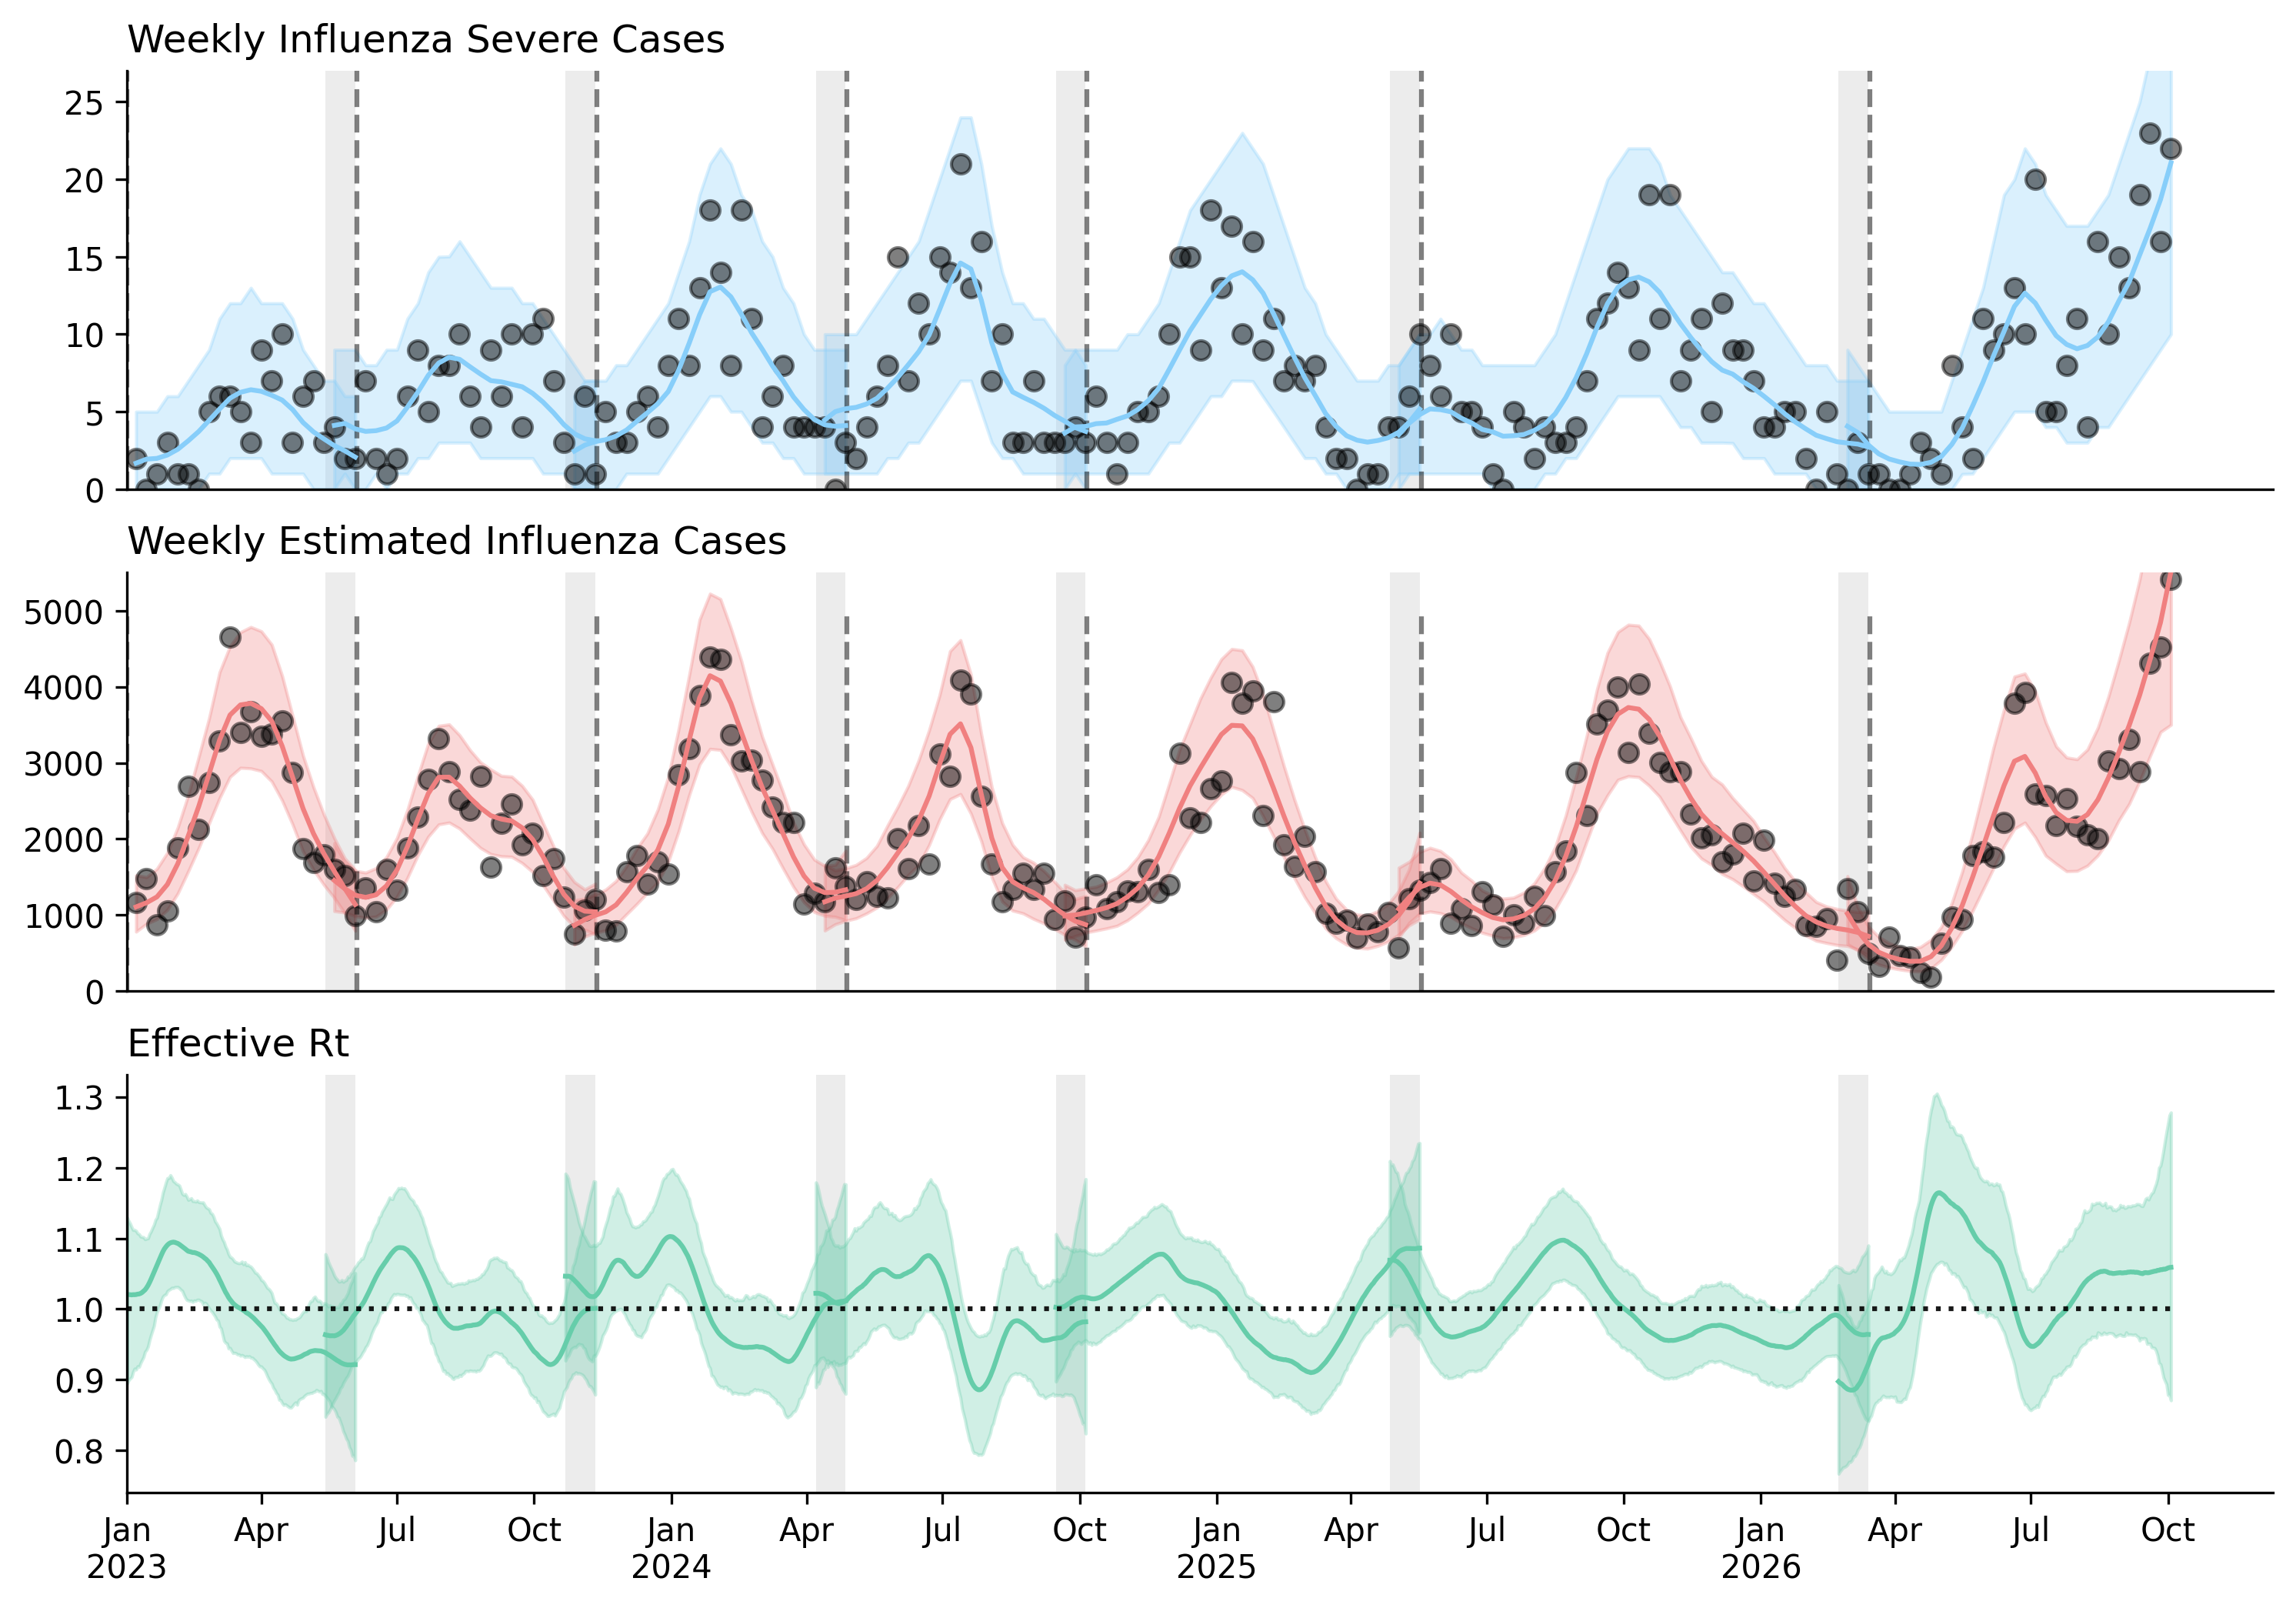

In [10]:
fig,ax = plt.subplots(3,1,figsize = (12,8),dpi=300)
plt.subplots_adjust(hspace = 0.2)

ax[0].plot(d['end_date'],d['severe_flu'], 'ko',alpha = 0.5)

for v in surv_period3['start']:
        ax[0].vlines(x = d[d['year_week'] == v]['start_date'], ymin = 0, ymax = 30, linestyles='dashed', alpha = 0.5, color = 'black')
        ax[1].vlines(x = d[d['year_week'] == v]['start_date'], ymin = 0, ymax = 5000, linestyles='dashed', alpha = 0.5, color = 'black')

ax[0].set_ylim(0,27)
ax[0].set_xticks([])

ax[1].plot(d['end_date'],d['est_flu_cases'],'ko', alpha = 0.5)

ax[1].set_ylim(0,5500)
ax[1].set_xticks([])

for a in ax:
        a.spines['top'].set_visible(False)      
        a.spines['right'].set_visible(False)

# shade burn-in weeks (fitted, but outside the surveillance period)
for idx in range(len(res_list)):
        if burn_list[idx] > 0:
                for a in ax:
                        a.axvspan(d_comb[idx]['start_date'].iloc[0], d_comb[idx]['end_date'].iloc[burn_list[idx] - 1],
                                  color = 'grey', alpha = 0.15, lw = 0)

for idx in range(len(res_list)):
        pred_pri = res_list[idx].posterior_predictive.negbinom_primary_rv.values.reshape(-1,len(res_list[idx].observed_data.negbinom_primary_rv.values),7).sum(axis=2)
        pred_sev = res_list[idx].posterior_predictive.negbinom_severe_rv.values.reshape(-1,len(res_list[idx].observed_data.negbinom_severe_rv.values),7).sum(axis=2)

        pred_pri_q = jnp.quantile(pred_pri, q = jnp.array([0.025,0.975]),axis=0)
        pred_sev_q = jnp.quantile(pred_sev, q = jnp.array([0.025,0.975]),axis=0)

        ax[0].plot(d_comb[idx]['end_date'],jnp.mean(pred_sev,axis=0), color = 'lightskyblue')
        ax[0].fill_between(d_comb[idx]['end_date'],pred_sev_q[0,],pred_sev_q[1,], color = 'lightskyblue', alpha = 0.3)

        ax[1].plot(d_comb[idx]['end_date'],jnp.mean(pred_pri,axis=0), color = 'lightcoral')
        ax[1].fill_between(d_comb[idx]['end_date'],pred_pri_q[0,],pred_pri_q[1,], color = 'lightcoral', alpha = 0.3)

        #Plot Rt
        xdate = pd.date_range(d_comb[idx]['start_date'].iloc[0],d_comb[idx]['end_date'].iloc[-1])
        est_rt = res_list[idx].posterior_predictive.Rt.values.reshape(-1,len(d_comb[idx]) * 7)
        rt_q = jnp.quantile(est_rt, q = jnp.array([0.025,0.975]),axis=0)

        ax[2].plot(xdate, jnp.mean(est_rt,axis=0), color = 'mediumaquamarine')
        ax[2].fill_between(xdate,rt_q[0,],rt_q[1,], color = 'mediumaquamarine', alpha = 0.3)

ax[2].hlines(y = 1.0, xmin = d['start_date'].iloc[0], xmax = d['end_date'].iloc[-1],linestyles='dotted', alpha = 0.9, color = 'black')

ax[0].set_title("Weekly Influenza Severe Cases", loc = 'left')
ax[1].set_title("Weekly Estimated Influenza Cases", loc = 'left')
ax[2].set_title("Effective Rt", loc = 'left')

format_quarterly_axis(ax[2])

for a in ax:
        a.set_xlim(d_comb[0]['start_date'].iloc[0])    
        
plt.show()

### Visualise infection to severe rate

In [11]:
def hdpi_samples(samples, cred_mass=0.95):
    """
    Compute highest-density posterior interval (HDPI) from samples.

    Parameters
    ----------
    samples : array-like
        1D array of samples (floats).
    cred_mass : float
        Credible mass between 0 and 1 (e.g. 0.95).

    Returns
    -------
    (lo, hi) : tuple
        Lower and upper bounds of the HDPI.
    """
    samples = np.asarray(samples)
    if samples.ndim != 1:
        raise ValueError("samples must be a 1D array")
    if not (0 < cred_mass < 1):
        raise ValueError("cred_mass must be between 0 and 1")

    n = samples.size
    if n == 0:
        return (np.nan, np.nan)

    # Number of samples inside interval
    k = int(np.floor(cred_mass * n))
    if k < 1:
        raise ValueError("cred_mass * n must be >= 1 (increase cred_mass or more samples)")

    # Sort samples
    sorted_samples = np.sort(samples)

    # Find minimal width interval among all windows of length k
    start_idx = np.arange(0, n - k + 1)
    end_idx = start_idx + k - 1  # inclusive index

    # widths for each candidate interval
    widths = sorted_samples[end_idx] - sorted_samples[start_idx]
    min_idx = np.argmin(widths)

    hdi_low = sorted_samples[start_idx[min_idx]]
    hdi_high = sorted_samples[end_idx[min_idx]]

    return float(hdi_low), float(hdi_high)

### Post-hoc scaling: ascertainment-assumption uncertainty

With the ascertainment chain fixed, each period's `p_severe_ihr` is identified by the data (delay-adjusted severe / polyclinic ratio). Its absolute level is conditional on `P_SYM`, `P_HSEEK`, `P_VISIT`, `P_RHO`. The cell below multiplies every period's posterior by the **same** draws of the multiplier `M = (p_sym p_hseek p_visit / p_rho) / (fixed value)`, using the former priors as the assumption distributions. Ratios between periods are unaffected by `M`.

In [12]:
## Post-hoc propagation of the ascertainment-assumption uncertainty (shared across periods)
from scipy.special import expit

rng = np.random.default_rng(0)
n_draws = res_list[0].posterior.p_severe_ihr.size

p_sym_d   = expit(rng.normal(0.85, 0.6, n_draws))   # former prior on p_sym  (logit-normal, median 0.70)
p_hseek_d = rng.beta(16, 24, n_draws)                # former prior on p_hseek (mean 0.40)
p_visit_d = rng.beta(20, 80, n_draws)                # former prior on p_visit (mean 0.20)
p_rho_d   = expit(rng.normal(1.39, 0.6, n_draws))   # former prior on p_rho  (logit-normal, median 0.80)

M = (p_sym_d * p_hseek_d * p_visit_d / p_rho_d) / (ALPHA_PRIMARY_FIXED / P_RHO)

ihr_fixed  = {f'SP{k+1}': r.posterior.p_severe_ihr.values.reshape(-1) for k, r in enumerate(res_list)}
ihr_scaled = {k: v * M for k, v in ihr_fixed.items()}   # same M for every period

print(f"Shared multiplier M: median {np.median(M):.2f}, "
      f"95% interval ({np.quantile(M, 0.025):.2f}, {np.quantile(M, 0.975):.2f})")

Shared multiplier M: median 0.96, 95% interval (0.44, 1.91)


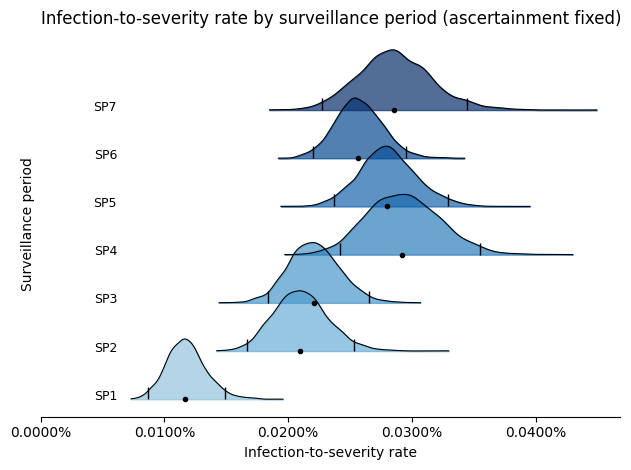

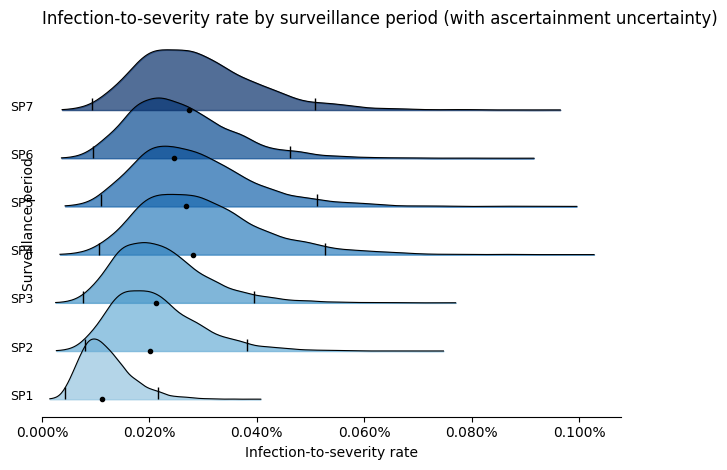

In [13]:
from scipy.stats import gaussian_kde
from matplotlib.ticker import PercentFormatter

def ridge_plot(samples_dict, title, cred = 0.95):
    """Ridge plot of posterior samples per surveillance period with median and HDPI markers."""
    fig, ax = plt.subplots()

    # Vertical spacing between ridges
    spacing = 0.8

    # Define color gradient
    colors = plt.cm.Blues(np.linspace(0.4, 1, len(samples_dict)))

    x_min = min(v.min() for v in samples_dict.values())
    x_max = max(v.max() for v in samples_dict.values())
    x_range = x_max - x_min

    for i, (label, values) in enumerate(samples_dict.items()):
        kde = gaussian_kde(values)
        x = np.linspace(values.min(), values.max(), 200)
        y = kde(x)
        y /= y.max()

        ax.fill_between(x, i * spacing, y + i * spacing, color=colors[i], alpha=0.7)
        ax.plot(x, y + i * spacing, color='black', lw=0.8)

        # adaptive offset: 3% of total range to the left
        ax.text(x_min - 0.03 * x_range, i * spacing + 0.05, label,
                fontsize=9, ha='right', va='center')

        # HDPI markers and median
        lo, hi = hdpi_samples(values, cred_mass=cred)
        med = np.median(values)
        ax.vlines([lo, hi], i*spacing, i*spacing + 0.2, color='k', lw=1)
        ax.plot(med, i*spacing, marker='o', markersize=3, color='k')

    # Clean up axes
    ax.set_xlabel('Infection-to-severity rate')
    ax.set_yticks([])
    ax.set_ylabel('Surveillance period')
    ax.set_xlim(left=0)
    ax.set_title(title, loc = 'left')

    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)

    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))

    plt.tight_layout()
    plt.show()

ridge_plot(ihr_fixed,  'Infection-to-severity rate by surveillance period (ascertainment fixed)')
ridge_plot(ihr_scaled, 'Infection-to-severity rate by surveillance period (with ascertainment uncertainty)')

In [14]:
## Summary: infection-to-severity rate per period (median, 95% HDPI) and ratio to SP1
print("Fixed ascertainment (data-identified given P_SYM, P_HSEEK, P_VISIT, P_RHO):")
for period, samples in ihr_fixed.items():
    lo, hi = hdpi_samples(samples)
    print(f"  {period} median: {np.median(samples):.4%} , 95% HPDI = ({lo:.4%}, {hi:.4%})")

print("\nWith ascertainment-assumption uncertainty (shared multiplier M):")
for period, samples in ihr_scaled.items():
    lo, hi = hdpi_samples(samples)
    print(f"  {period} median: {np.median(samples):.4%} , 95% HPDI = ({lo:.4%}, {hi:.4%})")

print("\nRatio to SP1 (identical with or without M):")
ref = ihr_fixed['SP1']
for period, samples in ihr_fixed.items():
    ratio = samples / ref
    lo, hi = hdpi_samples(ratio)
    print(f"  {period}/SP1 median: {np.median(ratio):.2f} , 95% HPDI = ({lo:.2f}, {hi:.2f})")

Fixed ascertainment (data-identified given P_SYM, P_HSEEK, P_VISIT, P_RHO):
  SP1 median: 0.0117% , 95% HPDI = (0.0087%, 0.0149%)
  SP2 median: 0.0210% , 95% HPDI = (0.0167%, 0.0253%)
  SP3 median: 0.0220% , 95% HPDI = (0.0184%, 0.0265%)
  SP4 median: 0.0292% , 95% HPDI = (0.0242%, 0.0355%)
  SP5 median: 0.0280% , 95% HPDI = (0.0237%, 0.0329%)
  SP6 median: 0.0256% , 95% HPDI = (0.0220%, 0.0295%)
  SP7 median: 0.0285% , 95% HPDI = (0.0227%, 0.0344%)

With ascertainment-assumption uncertainty (shared multiplier M):
  SP1 median: 0.0111% , 95% HPDI = (0.0042%, 0.0216%)
  SP2 median: 0.0201% , 95% HPDI = (0.0079%, 0.0382%)
  SP3 median: 0.0211% , 95% HPDI = (0.0076%, 0.0395%)
  SP4 median: 0.0281% , 95% HPDI = (0.0106%, 0.0527%)
  SP5 median: 0.0268% , 95% HPDI = (0.0110%, 0.0512%)
  SP6 median: 0.0246% , 95% HPDI = (0.0095%, 0.0461%)
  SP7 median: 0.0274% , 95% HPDI = (0.0094%, 0.0508%)

Ratio to SP1 (identical with or without M):
  SP1/SP1 median: 1.00 , 95% HPDI = (1.00, 1.00)
  SP2/SP

### Sanity check: plain severe / polyclinic-case ratio

Severe cases over polyclinic-attributed cases within each surveillance period (burn-in excluded), scaled by the fixed ascertainment chain. Lag 1 shifts severe cases one week later than polyclinic cases. The model medians should sit within roughly 20% of these.

In [15]:
## Plain delay-adjusted ratio vs model median, per period
rows = []
for k, d_core in enumerate(d_core_list):
    sev = d_core['severe_flu'].values.astype(float)
    pri = np.round(d_core['est_flu_cases'].values)
    r0 = sev.sum() / pri.sum()               # same weeks
    r1 = sev[1:].sum() / pri[:-1].sum()      # severe lagged one week after polyclinic cases
    rows.append({
        'period': f'SP{k+1}',
        'weeks': len(d_core),
        'severe': int(sev.sum()),
        'poly_cases': int(pri.sum()),
        'ratio_lag0': r0 * ALPHA_PRIMARY_FIXED / P_RHO,
        'ratio_lag1': r1 * ALPHA_PRIMARY_FIXED / P_RHO,
        'model_median': np.median(ihr_fixed[f'SP{k+1}']),
    })

check = pd.DataFrame(rows)
check['model_vs_lag0'] = check['model_median'] / check['ratio_lag0']

fmt = check.copy()
for col in ['ratio_lag0', 'ratio_lag1', 'model_median']:
    fmt[col] = fmt[col].map('{:.4%}'.format)
fmt['model_vs_lag0'] = fmt['model_vs_lag0'].map('{:.2f}'.format)
print(fmt.to_string(index=False))

period  weeks  severe  poly_cases ratio_lag0 ratio_lag1 model_median model_vs_lag0
   SP1     22      86       51637    0.0117%    0.0116%      0.0117%          1.00
   SP2     23     136       44000    0.0216%    0.0211%      0.0210%          0.97
   SP3     24     172       53921    0.0223%    0.0222%      0.0220%          0.99
   SP4     23     189       41489    0.0319%    0.0323%      0.0292%          0.92
   SP5     32     236       58004    0.0285%    0.0284%      0.0280%          0.98
   SP6     43     278       77611    0.0251%    0.0245%      0.0256%          1.02
   SP7     29     262       62692    0.0293%    0.0319%      0.0285%          0.98


### Burn-in sensitivity (SP2)

Refit one period without the backward burn-in extension and compare `p_severe_ihr`.

In [16]:
## Sensitivity: refit SP2 with no burn-in extension (~1-2 min) and compare to the 3-week version
idx = 1   # SP2
pos0 = d.index[d['year_week'] == surv_period3['start'][idx]][0]
end_idx = d.index[d['year_week'] == surv_period3['end'][idx]][0]
d_sub0 = d.iloc[pos0:end_idx + 1]
y_sev0 = d_sub0['severe_flu'].values.astype(int)
y_pri0 = np.round(d_sub0['est_flu_cases'].values).astype(int)

fit0 = model.SeverePrimaryModel(
    latent_infections_rv=latent_inf,
    latent_severe_primary_rv=latent_severeprimary,
    I0_rv=make_I0(y_pri0[0]),
    gen_int_rv=gen_time_rv,
    Rt_process_rv=rtproc,
    severe_admission_obs_process_rv=obs_sev,
    primary_care_cases_obs_process_rv=obs_primary
)
fit0.run(
    num_samples=1000,
    num_warmup=1000,
    rng_key=jax.random.key(54),
    mcmc_args=dict(progress_bar=False, num_chains=4),
    data_observed_severe_admissions = y_sev0,
    data_observed_primary_care_cases = y_pri0,
    weekly_obs = True
)

s0 = az.from_numpyro(posterior=fit0.mcmc).posterior.p_severe_ihr.values.reshape(-1)
s3 = ihr_fixed[f'SP{idx+1}']
for label, s in [('burn-in 0 weeks', s0), (f'burn-in {burn_list[idx]} weeks', s3)]:
    lo, hi = hdpi_samples(s)
    print(f"SP{idx+1} {label}: median {np.median(s):.4%}, 95% HPDI ({lo:.4%}, {hi:.4%})")
print(f"median shift (3-week vs none): {np.median(s3) / np.median(s0) - 1:+.1%}")

SP2 burn-in 0 weeks: median 0.0219%, 95% HPDI (0.0176%, 0.0274%)
SP2 burn-in 3 weeks: median 0.0210%, 95% HPDI (0.0167%, 0.0253%)
median shift (3-week vs none): -4.0%
